# B1850 Rotation-Rate Experiment — Analysis Notebook

**Project:** Sensitivity of cloud distribution and planetary albedo to rotation rate,
with ocean–atmosphere coupling (B1850), compared to the atmosphere-only F2000climo
results from the previous assignment.

**Cases:**
- Control ($\Omega_0$) — `dmyeong.as.b1850.omega1`
- $0.5\times\Omega_0$ — `dmyeong.as.b1850.omega0.5x`
- $2.0\times\Omega_0$ — `dmyeong.as.b1850.omega2x`

In [2]:
import glob
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

xr.set_options(keep_attrs=True)
plt.rcParams['figure.dpi'] = 110


In [3]:
CASES = {
    'Control':  '/orcd/pool/005/abodner_shared/dmyeong/b1850_omega1',
    '0.5xOmega': '/orcd/pool/005/abodner_shared/dmyeong/b1850_omega05',
    '2.0xOmega': '/orcd/pool/005/abodner_shared/dmyeong/b1850_omega2',
}

# Colors should be consistent across all plots
COLORS = {
    'Control': 'black',
    '0.5xOmega': 'tab:blue',
    '2.0xOmega': 'tab:red',
}

# Variables requested in fincl1 (user_nl_cam)
VARS_OF_INTEREST = [
    'SOLIN', 'FSNTOA', 'FLNT', 'CLDTOT', 'CLDLOW', 'CLDMED', 'CLDHGH',
    'TMQ', 'QREFHT', 'TS', 'TREFHT', 'PSL', 'PRECT',
    'LHFLX', 'SHFLX', 'ICEFRAC', 'OCNFRAC', 'LANDFRAC',
]

OUTDIR = '/tmp/b1850_analysis_outputs'
os.makedirs(OUTDIR, exist_ok=True)


## 2. Find available monthly history files per case



In [4]:
file_lists = {}
for name, path in CASES.items():
    files = sorted(glob.glob(f'{path}/atm/hist/*.h0.*.nc'))
    file_lists[name] = files
    n = len(files)
    first = files[0].split('.h0.')[-1].replace('.nc', '') if files else None
    last  = files[-1].split('.h0.')[-1].replace('.nc', '') if files else None
    print(f'{name:12s}: {n:3d} months available   (first={first}, last={last})')


Control     :  80 months available   (first=0001-01, last=0007-08)
0.5xOmega   :  75 months available   (first=0001-01, last=0007-03)
2.0xOmega   :  75 months available   (first=0001-01, last=0007-03)


## 3. Load datasets


In [ ]:
def load_case(files, varlist=VARS_OF_INTEREST):
    datasets = []
    for f in files:
        d = xr.open_dataset(f, decode_times=True)
        keep = [v for v in varlist if v in d.variables]
        datasets.append(d[keep].load())
        d.close()
    out = xr.concat(datasets, dim='time')
    return out.sortby('time')

ds = {}
for name, files in file_lists.items():
    if len(files) == 0:
        print(f'WARNING: no files found for {name}, skipping.')
        continue
    print(f'Loading {name} ({len(files)} files)...')
    ds[name] = load_case(files)

print()
print('Loaded cases:', list(ds.keys()))


Loading Control (80 files)...
Loading 0.5xOmega (75 files)...
Loading 2.0xOmega (75 files)...

Loaded cases: ['Control', '0.5xOmega', '2.0xOmega']


## 4. Helper functions: area-weighted global mean, zonal mean, albedo


In [ ]:
def global_mean(da):
    weights = np.cos(np.deg2rad(da['lat']))
    weights.name = 'weights'
    return da.weighted(weights).mean(dim=['lat', 'lon'])

def zonal_mean(da):
    return da.mean(dim='lon')

def compute_albedo(dset):
    return (dset['SOLIN'] - dset['FSNTOA']) / dset['SOLIN']

for name in ds:
    ds[name]['ALBEDO'] = compute_albedo(ds[name])
    ds[name]['ALBEDO'].attrs['long_name'] = 'TOA albedo'
    ds[name]['ALBEDO'].attrs['units'] = 'fraction'


## 5. Spin-up assessment


--- Control ---
Annual-mean global TS (K):
year
1    288.397
2    287.991
3    288.223
4    288.409
5    288.329
6    288.560
7    287.122
Name: TS, dtype: float64
Year-over-year difference (K):
year
2   -0.407
3    0.233
4    0.186
5   -0.079
6    0.231
Name: TS, dtype: float64

--- 0.5xOmega ---
Annual-mean global TS (K):
year
1    288.412
2    287.748
3    287.751
4    287.761
5    287.570
6    287.518
7    285.735
Name: TS, dtype: float64
Year-over-year difference (K):
year
2   -0.664
3    0.003
4    0.011
5   -0.191
6   -0.052
Name: TS, dtype: float64

--- 2.0xOmega ---
Annual-mean global TS (K):
year
1    289.057
2    289.761
3    290.096
4    290.763
5    291.322
6    291.747
7    290.243
Name: TS, dtype: float64
Year-over-year difference (K):
year
2    0.703
3    0.335
4    0.668
5    0.559
6    0.426
Name: TS, dtype: float64



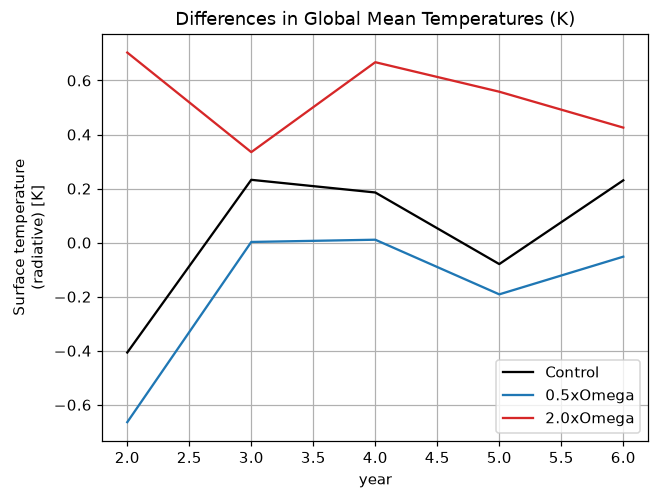

In [21]:
# cutting the data for the minimum length of run across all three cases
min_len = min(ds[name].sizes['time'] for name in ds)
num_years = min_len // 12

# deciding how many initial months to discard before the analysis window
ds_analysis = {}
for name in ds:
    ds_analysis[name] = ds[name].isel(time=slice(None, num_years*12))
    ts_gm = global_mean(ds_analysis[name]['TS'])
    annual = ts_gm.groupby('time.year').mean('time')
    diffs = annual.diff('year')
    diffs_trimmed = diffs.sel(year=slice(2, 6))
    diffs_trimmed.plot(label=name, color=COLORS[name])
    print(f'--- {name} ---')
    print('Annual-mean global TS (K):')
    print(annual.to_series().round(3))
    print('Year-over-year difference (K):')
    print(diffs_trimmed.to_series().round(3))
    print() 

plt.title("Differences in Global Mean Temperatures (K)")
plt.legend()
plt.grid()

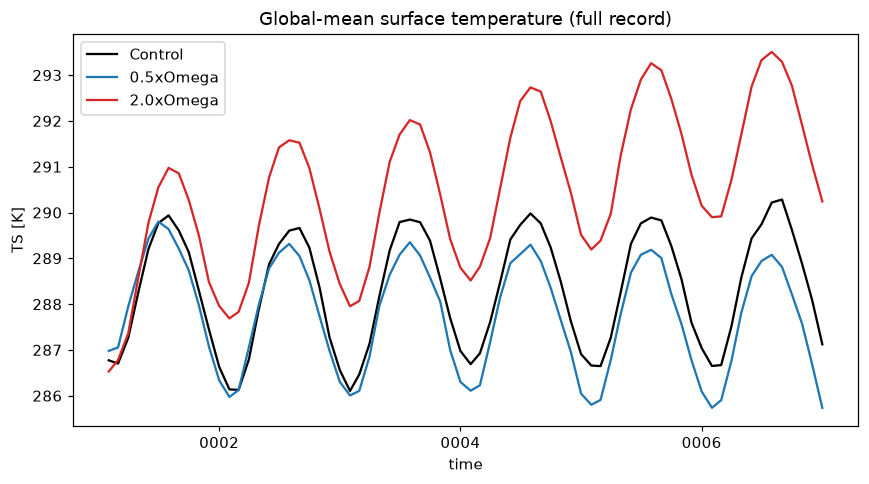

In [8]:
# Plot global-mean TS over the full available record to visually confirm
# when the initial adjustment settles down.
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ds_analysis:
    global_mean(ds_analysis[name]['TS']).plot(ax=ax, label=name, color=COLORS[name])
ax.set_title('Global-mean surface temperature (full record)')
ax.set_ylabel('TS [K]')
ax.legend()
plt.tight_layout()
plt.savefig(f'{OUTDIR}/TS_full_record_spinup_check.png')
plt.show()


## 6. Define spin-up period and analysis window


In [9]:
# Defining spin-up period and truncate the analysis window across all three cases
SPINUP_MONTHS = 24

# Setting the analysis length to 36 months without 2 months lagging behind a complete year
analysis_len = 48

for name in ds:
    ds_analysis[name] = ds_analysis[name].isel(time=slice(SPINUP_MONTHS-1, SPINUP_MONTHS+analysis_len-1))
    t0 = str(ds_analysis[name].time.values[0])[:7]
    t1 = str(ds_analysis[name].time.values[-1])[:7]
    print(f'{name:12s}: analysis window {t0} to {t1}  ({ds_analysis[name].sizes["time"]} months)')


Control     : analysis window 0003-01 to 0006-12  (48 months)
0.5xOmega   : analysis window 0003-01 to 0006-12  (48 months)
2.0xOmega   : analysis window 0003-01 to 0006-12  (48 months)


## 7. Global-mean time series over the analysis window

Quick multi-panel check of TS, CLDTOT, ALBEDO, and FSNTOA for all three
cases over the common analysis period.


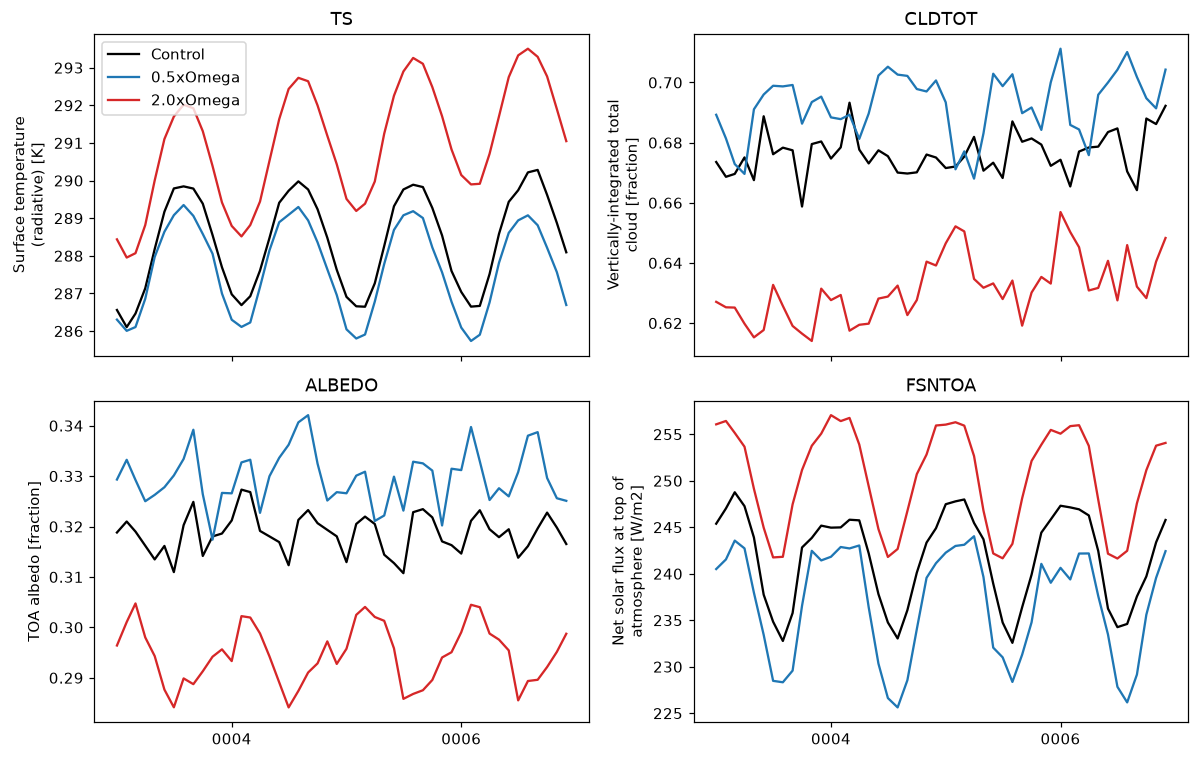

In [10]:
plot_vars = ['TS', 'CLDTOT', 'ALBEDO', 'FSNTOA']

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, var in zip(axes.flat, plot_vars):
    for name in ds_analysis:
        global_mean(ds_analysis[name][var]).plot(ax=ax, label=name, color=COLORS[name])
    ax.set_title(var)
    ax.set_xlabel('')
axes.flat[0].legend()
plt.tight_layout()
plt.savefig(f'{OUTDIR}/global_mean_timeseries_analysis_window.png')
plt.show()


## 8. Summary table: time-mean global values


In [11]:
summary_vars = ['TS', 'CLDTOT', 'CLDLOW', 'CLDMED', 'CLDHGH', 'ALBEDO',
                'SOLIN', 'FSNTOA', 'PRECT', 'TMQ']

rows = []
for name in ds_analysis:
    row = {'Case': name}
    for var in summary_vars:
        if var in ds_analysis[name]:
            gm = global_mean(ds_analysis[name][var])
            row[f'{var}_mean'] = float(gm.mean())
            row[f'{var}_std']  = float(gm.std())
    rows.append(row)

summary_df = pd.DataFrame(rows).set_index('Case')
summary_df_rounded = summary_df.round(4)
summary_df_rounded.to_csv(f'{OUTDIR}/summary_table.csv')
summary_df_rounded


,TS_mean,TS_std,CLDTOT_mean,CLDTOT_std,CLDLOW_mean,CLDLOW_std,CLDMED_mean,CLDMED_std,CLDHGH_mean,CLDHGH_std,ALBEDO_mean,ALBEDO_std,SOLIN_mean,SOLIN_std,FSNTOA_mean,FSNTOA_std,PRECT_mean,PRECT_std,TMQ_mean,TMQ_std
Case,,,,,,,,,,,,,,,,,,,,
Control,288.3804,1.2626,0.6763,0.0071,0.4091,0.0120,0.2827,0.0083,0.4136,0.0109,0.3187,0.0039,340.2653,7.967,241.7916,4.9411,0.0,0.0,24.2785,0.9468
0.5xOmega,287.6502,1.1906,0.6925,0.0104,0.4342,0.0174,0.2835,0.0113,0.3881,0.0173,0.3298,0.0054,340.2653,7.967,236.7755,5.8125,0.0,0.0,20.4158,0.9496
2.0xOmega,290.9820,1.5665,0.6315,0.0105,0.3434,0.0127,0.2747,0.0097,0.4219,0.0128,0.2946,0.0058,340.2653,7.967,250.4442,5.3428,0.0,0.0,33.5717,2.2085


In [ ]:
# Differences relative to control
if 'Control' in summary_df.index:
    diff_rows = {}
    for name in summary_df.index:
        if name == 'Control':
            continue
        diff_rows[f'{name} - Control'] = summary_df.loc[name] - summary_df.loc['Control']
    diff_df = pd.DataFrame(diff_rows).T
    mean_cols = [c for c in diff_df.columns if c.endswith('_mean')]
    diff_df = diff_df[mean_cols].round(4)
    diff_df.to_csv(f'{OUTDIR}/difference_from_control.csv')
diff_df


,TS_mean,CLDTOT_mean,CLDLOW_mean,CLDMED_mean,CLDHGH_mean,ALBEDO_mean,SOLIN_mean,FSNTOA_mean,PRECT_mean,TMQ_mean
0.5xOmega - Control,-0.7302,0.0162,0.0251,0.0008,-0.0255,0.0111,0.0,-5.0162,-0.0,-3.8627
2.0xOmega - Control,2.6016,-0.0448,-0.0657,-0.0080,0.0083,-0.0241,0.0,8.6525,0.0,9.2933


## 9. Zonal-mean cloud fraction (time-mean over analysis window)


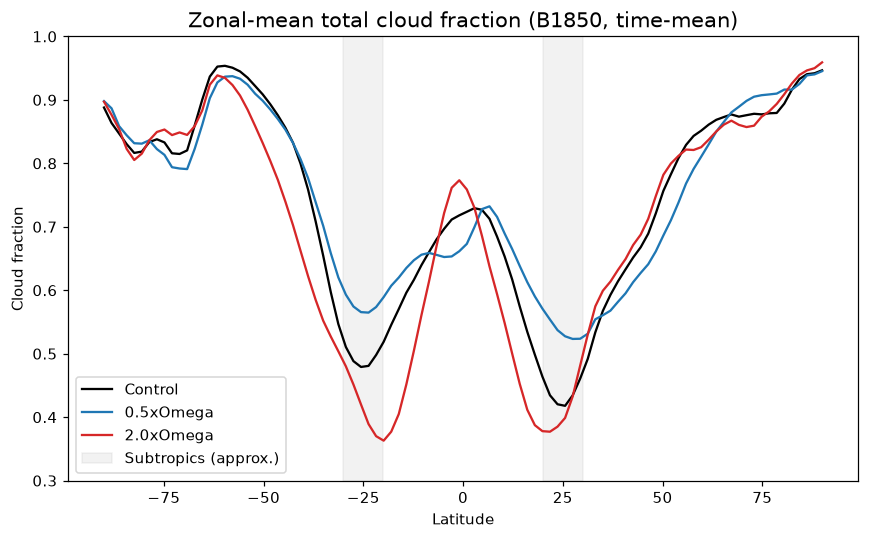

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in ds_analysis:
    zm = zonal_mean(ds_analysis[name]['CLDTOT']).mean('time')
    ax.plot(zm['lat'], zm, label=name, color=COLORS[name])
ax.set_xlabel('Latitude')
ax.set_ylim(0.3, 1.0)
ax.set_ylabel('Cloud fraction')
ax.set_title('Zonal-mean total cloud fraction (B1850, time-mean)', fontsize=14)
ax.axvspan(20, 30, color='gray', alpha=0.1, label='Subtropics (approx.)')
ax.axvspan(-30, -20, color='gray', alpha=0.1)
ax.legend()
plt.tight_layout()
plt.savefig(f'{OUTDIR}/zonal_mean_CLDTOT.png')
plt.show()


## 10. Spatial maps: time-mean albedo and differences from control

Panel (A): time-mean albedo map for each case.
Panels (B)/(C): albedo difference relative to control (perturbation − control).


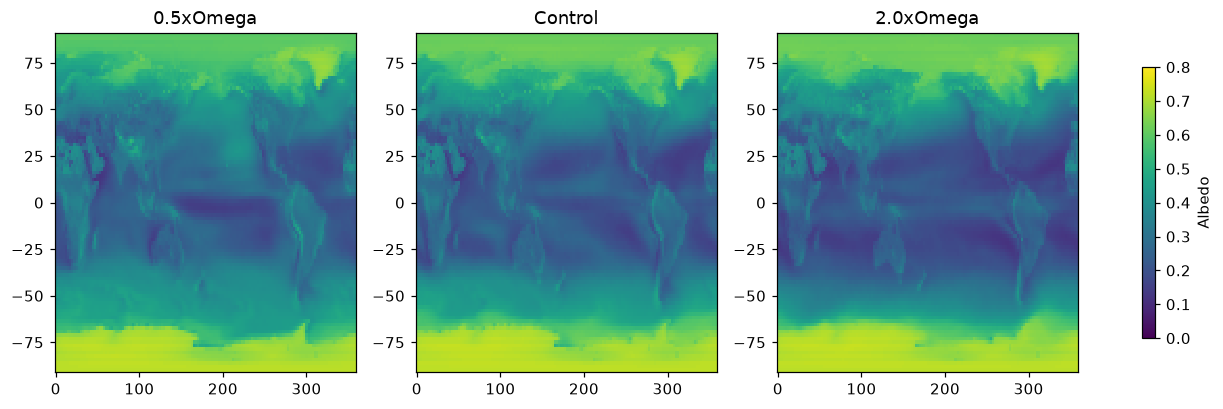

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
vmin, vmax = 0.0, 0.8
im = None
for ax, name in zip(axes, ['0.5xOmega', 'Control', '2.0xOmega']):
    if name not in ds_analysis:
        continue
    field = ds_analysis[name]['ALBEDO'].mean('time')
    im = ax.pcolormesh(field['lon'], field['lat'], field, vmin=vmin, vmax=vmax, cmap='viridis')
    ax.set_title(name)
if im is not None:
    fig.colorbar(im, ax=axes, orientation='vertical', shrink=0.8, label='Albedo')
plt.savefig(f'{OUTDIR}/albedo_maps_panel_A.png', bbox_inches='tight')
plt.show()


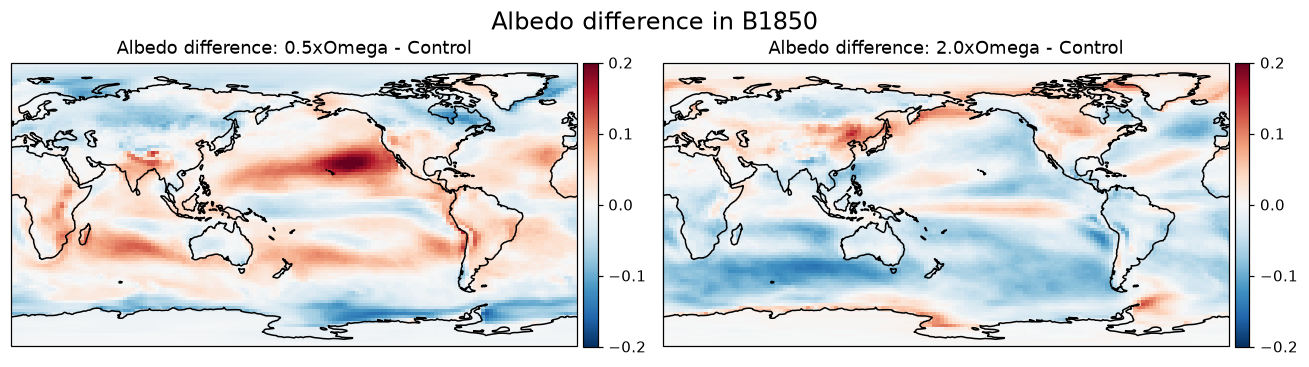

In [15]:
import cartopy.crs as ccrs
if 'Control' in ds_analysis:
    ctrl_alb = ds_analysis['Control']['ALBEDO'].mean('time')

    fig, axes = plt.subplots(
        1, 2, 
        figsize=(12, 4.5), 
        subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)}
    )
    
    diff_specs = [('0.5xOmega', axes[0]), ('2.0xOmega', axes[1])]
    
    for name, ax in diff_specs:
        if name not in ds_analysis:
            continue
            
        diff = ds_analysis[name]['ALBEDO'].mean('time') - ctrl_alb
        
        im = ax.pcolormesh(
            diff['lon'], diff['lat'], diff,
            vmin=-0.2, vmax=0.2, cmap='RdBu_r',
            transform=ccrs.PlateCarree()
        )
        
        ax.set_title(f'Albedo difference: {name} - Control')
        ax.coastlines()
        
        cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.0242, pad=0.01)
        cbar.set_ticks([-0.2, -0.1, 0.0, 0.1, 0.2])
        cbar.ax.set_ylim(-0.2, 0.2)
        
    fig.suptitle("Albedo difference in B1850", fontsize=16, y=0.85)
    plt.tight_layout()
    plt.savefig(f'{OUTDIR}/albedo_diff_maps_panel_BC.png')
    plt.show()

## 11. Seasonal cycle (monthly climatology) over the analysis window

Climatological monthly mean for global albedo, cloud fraction, and
surface temperature — comparable to Project 1's seasonality figure.


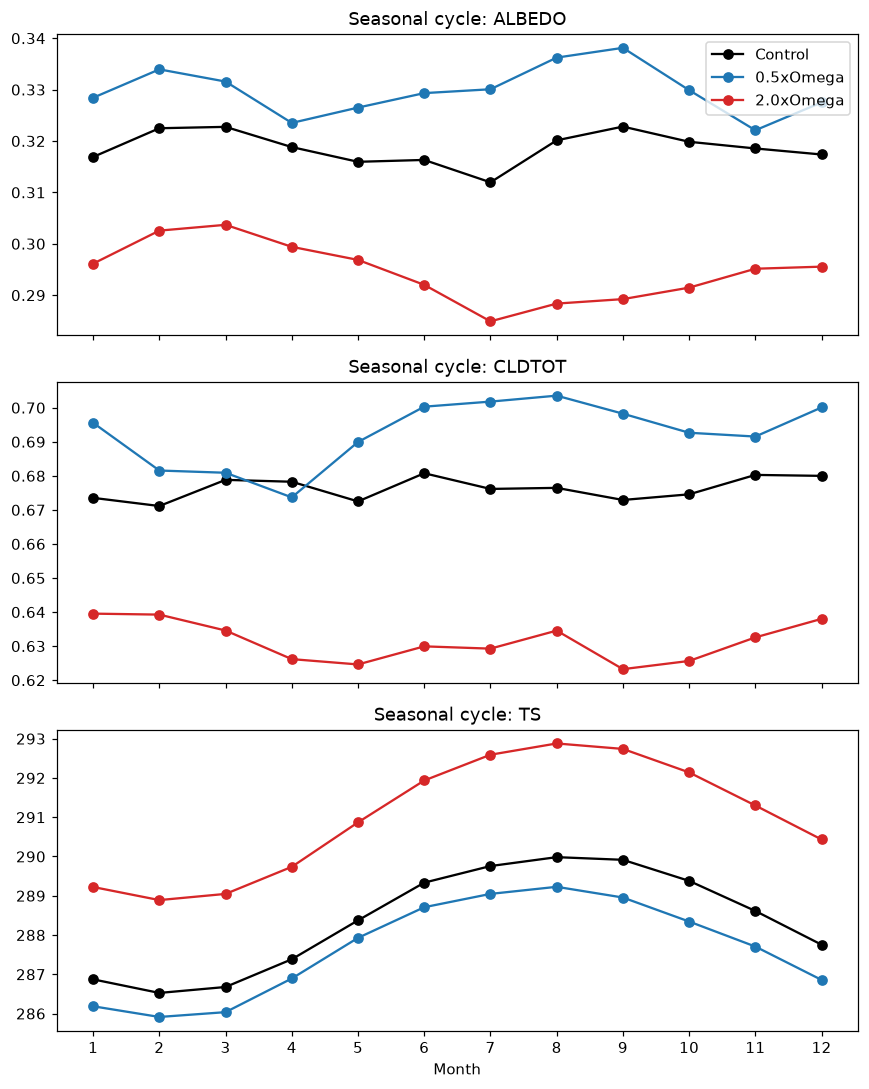

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
season_vars = ['ALBEDO', 'CLDTOT', 'TS']

for ax, var in zip(axes, season_vars):
    for name in ds_analysis:
        gm = global_mean(ds_analysis[name][var])
        clim = gm.groupby('time.month').mean('time')
        ax.plot(clim['month'], clim, marker='o', label=name, color=COLORS[name])
    ax.set_title(f'Seasonal cycle: {var}')
    ax.set_xticks(range(1, 13))

axes[0].legend()
axes[-1].set_xlabel('Month')
plt.tight_layout()
plt.savefig(f'{OUTDIR}/seasonal_cycle_panels.png')
plt.show()


## 12. Comparison vs. Project 1 (F2000climo)


In [17]:
project1_numbers = {
    'Control_albedo': 0.294,
    '0.5x_albedo':    0.314,
    '2.0x_albedo':    0.263,
}

project2_numbers = {
    'Control_albedo': float(summary_df.loc['Control', 'ALBEDO_mean']) if 'Control' in summary_df.index else np.nan,
    '0.5x_albedo':    float(summary_df.loc['0.5xOmega', 'ALBEDO_mean']) if '0.5xOmega' in summary_df.index else np.nan,
    '2.0x_albedo':    float(summary_df.loc['2.0xOmega', 'ALBEDO_mean']) if '2.0xOmega' in summary_df.index else np.nan,
}

comparison = pd.DataFrame({
    'F2000climo (Project 1)': project1_numbers,
    'B1850 (this project)': project2_numbers,
})
comparison['Difference (coupled - atm-only)'] = (
    comparison['B1850 (this project)'] - comparison['F2000climo (Project 1)']
)
comparison.round(4)


,F2000climo (Project 1),B1850 (this project),Difference (coupled - atm-only)
Control_albedo,0.294,0.3187,0.0247
0.5x_albedo,0.314,0.3298,0.0158
2.0x_albedo,0.263,0.2946,0.0316


## 13. Damping Factor ##

In [18]:
import pandas as pd

data = {
    'Case': ['Control', '0.5xOmega', '2.0xOmega'],
    'alpha_F2000': [0.294, 0.314, 0.263],
    'alpha_B1850': [0.319, 0.329, 0.294],
}
df = pd.DataFrame(data)
df['delta_F2000'] = df['alpha_F2000'] - df['alpha_F2000'][0]
df['delta_B1850'] = df['alpha_B1850'] - df['alpha_B1850'][0]
df['damping_ratio'] = df['delta_B1850'] / df['delta_F2000']
print(df)

        Case  alpha_F2000  alpha_B1850  delta_F2000  delta_B1850  \
0    Control        0.294        0.319        0.000        0.000   
1  0.5xOmega        0.314        0.329        0.020        0.010   
2  2.0xOmega        0.263        0.294       -0.031       -0.025   

   damping_ratio  
0            NaN  
1       0.500000  
2       0.806452  


## 14. Sea-ice Albedo ##

In [19]:
for name in ds_analysis:
    w = np.cos(np.deg2rad(ds_analysis[name].lat))
    icefrac = ds_analysis[name]['ICEFRAC'].weighted(w).mean(dim=['lat','lon','time'])
    print(name, float(icefrac.values))

Control 0.04334939262491838
0.5xOmega 0.02661462436732979
2.0xOmega 0.047424277914662694
